# Реализация и сравнение 5 методов Machine Unlearning относительно облака оракулов

В ноутбуке реализованы и сопоставлены **5 методов разобучения (Machine Unlearning)** для задачи удаления целого класса ($c_{\text{forget}} = 0$, `airplane`) на CIFAR-10. В качестве исходной модели берётся одна базовая модель из облака (`full-baseline/init_7_train_7`, эпоха 30), а в качестве эталона «истинного забывания» используется **облако из 16 оракулов** (`retain-oracle-c0`, сетка сидов `init_seed` $\in \{7, 42, 101, 2026\} \times$ `train_seed` $\in \{7, 42, 101, 2026\}$), обученных с нуля без класса `airplane`.

### Рассматриваемые методы

| № | Метод | Публикация / источник | Где вмешивается | Требует градиентов | Ключевая идея |
| :- | :--- | :--- | :--- | :-: | :--- |
| **1** | **Moment Transport** *(кастомный метод проекта)* | `class_geometry_unlearning.md` (2026) | Голова (`head[4]`) через статистику `S2_embedding` | Нет (замкнутая форма) | Обеление и перекраска первых и вторых моментов класса: $A = \Sigma_r^{1/2}\Sigma_c^{-1/2}$, $\tilde{h} = \mu_r + A(h - \mu_c)$ |
| **2** | **POUR-P** *(Provably Optimal Unlearning of Representations)* | Le et al., **CVPR 2026** ([arXiv:2511.19339](https://arxiv.org/abs/2511.19339)) | Проекция симплекс-ETF в `head[4]` / `S2_embedding` | Нет (замкнутая форма) | Ортогональная проекция $P = I - v_u v_u^\top$ вдоль направления забываемого класса сохраняет симплекс-ETF остальных $K-1$ классов |
| **3** | **DAMP** *(Depth-Aware Modulation by Projection)* | Hatami et al., **CVPRW 2026** ([arXiv:2604.15166](https://arxiv.org/abs/2604.15166)) | Все слои сети (`S5_block1` $\to$ `S1_logits`) | Нет (one-shot хирургия весов) | Послойное удаление невязки прототипа забываемого класса ортогонально линейной оболочке сохранённых прототипов с глубинным скейлингом $\alpha_\ell$ и без сдвига bias |
| **4** | **NegMerge** *(Sign-Consensual Weight Merging)* | Kim et al., **ICML 2025** ([arXiv:2410.05583](https://arxiv.org/abs/2410.05583)) | Весовое пространство всей сети ($\theta$) | Да (короткие прогоны на $D_f$) | Агрегация нескольких task-векторов $\tau_k = \theta_{\text{ft}}^{(k)} - \theta_{\text{base}}$ по фильтру совпадения знаков $\mathbb{1}_{\text{sign-consistent}}$ и вычитание $\theta - \lambda \tau_{\text{merged}}$ |
| **5** | **SCAR** *(Mahalanobis Feature Realignment + JS Distillation)* | Bonato et al., **ECCV 2024** ([arXiv:2404.12922](https://arxiv.org/abs/2404.12922)) | Ствол + голова (`features`, `head`) | Да (metric learning + дистилляция) | Стягивание признаков $D_f$ к ближайшему чужому классу по расстоянию Махаланобиса (с регуляризованной ковариацией) + температурная JS-дистилляция |

## 1. Импорты и настройка окружения

In [1]:
from __future__ import annotations

import copy
import time
from dataclasses import dataclass
from pathlib import Path
from typing import override

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn.functional as F
from torch import Tensor, nn
from torchvision import datasets

SEED: int = 7
FORGET_CLASS: int = 0
NUM_CLASSES: int = 10
EMBEDDING_DIM: int = 128
BATCH_SIZE: int = 256

INIT_SEEDS: tuple[int, ...] = (7, 42, 101, 2026)
TRAIN_SEEDS: tuple[int, ...] = (7, 42, 101, 2026)
BASE_RUN_NAME: str = "init_7_train_7"

CLOUD_HANDLE_ROOT: str = "ycalkk/convolutional-unlearning-cloud/pyTorch"
DATASET_HANDLE: str = "pankrzysiu/cifar10-python"

CIFAR10_MEAN: tuple[float, float, float] = (0.4914, 0.4822, 0.4465)
CIFAR10_STD: tuple[float, float, float] = (0.2023, 0.1994, 0.2010)
CLASS_NAMES: list[str] = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck",
]


def set_seed(seed: int = SEED) -> None:
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)


set_seed(SEED)
torch.set_num_threads(2)

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "figure.figsize": (12, 5.5),
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.titlesize": 11,
    }
)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 4)

## 2. Архитектура модели, данные CIFAR-10 и загрузка облака оракулов

Загружаем:
- **Базовую модель** `full-baseline/init_7_train_7` (эпоха 30) из облака `ycalkk/convolutional-unlearning-cloud`.
- **Облако из 16 оракулов** `retain-oracle-c0` (`init_{7,42,101,2026}_train_{7,42,101,2026}`, эпоха 30), обученных без класса `airplane` ($c = 0$).

In [2]:
class ConvolutionalModel(nn.Module):
    def __init__(self, num_classes: int = NUM_CLASSES) -> None:
        super().__init__()
        self.features: nn.Module = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((4, 4)),
        )
        self.head: nn.Module = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes),
        )

    @override
    def forward(self, x: Tensor) -> Tensor:
        return self.head(self.features(x))


def resolve_cloud_run_file(variation: str, run_name: str, filename: str) -> Path:
    handle = f"{CLOUD_HANDLE_ROOT}/{variation}"
    cache_candidate = (
        Path.home()
        / ".cache"
        / "kagglehub"
        / "models"
        / "ycalkk"
        / "convolutional-unlearning-cloud"
        / "pyTorch"
        / variation
        / "1"
        / run_name
        / filename
    )
    if cache_candidate.is_file():
        return cache_candidate
    try:
        root = Path(kagglehub.model_download(handle))
        candidate = root / run_name / filename
        if candidate.is_file():
            return candidate
    except Exception:
        pass
    downloaded = kagglehub.model_download(handle, path=f"{run_name}/{filename}")
    return Path(downloaded)


def load_cloud_model(
    variation: str, run_name: str, epoch: int = 30
) -> ConvolutionalModel:
    weights_path = resolve_cloud_run_file(
        variation, run_name, f"weights_epoch_{epoch:02d}.pt"
    )
    model = ConvolutionalModel()
    state = torch.load(weights_path, map_location="cpu", weights_only=True)
    model.load_state_dict(state)
    model.eval()
    return model.to(memory_format=torch.channels_last)


def load_cifar10_tensors() -> tuple[Tensor, Tensor, Tensor, Tensor]:
    dataset_root = Path(kagglehub.dataset_download(DATASET_HANDLE))
    raw_train = datasets.CIFAR10(root=str(dataset_root), train=True)
    raw_test = datasets.CIFAR10(root=str(dataset_root), train=False)

    mean = torch.tensor(CIFAR10_MEAN, dtype=torch.float32).view(1, 3, 1, 1)
    std = torch.tensor(CIFAR10_STD, dtype=torch.float32).view(1, 3, 1, 1)

    train_x = (
        (torch.from_numpy(raw_train.data).permute(0, 3, 1, 2).float() / 255.0 - mean)
        / std
    ).to(memory_format=torch.channels_last)
    train_y = torch.tensor(raw_train.targets, dtype=torch.long)

    test_x = (
        (torch.from_numpy(raw_test.data).permute(0, 3, 1, 2).float() / 255.0 - mean)
        / std
    ).to(memory_format=torch.channels_last)
    test_y = torch.tensor(raw_test.targets, dtype=torch.long)
    return train_x, train_y, test_x, test_y


t0 = time.perf_counter()
train_x, train_y, test_x, test_y = load_cifar10_tensors()
base_model = load_cloud_model("full-baseline", BASE_RUN_NAME)

oracle_run_names = [f"init_{i}_train_{t}" for i in INIT_SEEDS for t in TRAIN_SEEDS]
oracle_cloud: dict[str, ConvolutionalModel] = {
    run_name: load_cloud_model(f"retain-oracle-c{FORGET_CLASS}", run_name)
    for run_name in oracle_run_names
}

print(
    f"Загружены CIFAR-10 (train={tuple(train_x.shape)}, test={tuple(test_x.shape)}), "
    f"базовая модель '{BASE_RUN_NAME}' и облако из {len(oracle_cloud)} оракулов "
    f"класса {FORGET_CLASS} ({CLASS_NAMES[FORGET_CLASS]}) за {time.perf_counter() - t0:.2f} с."
)

Загружены CIFAR-10 (train=(50000, 3, 32, 32), test=(10000, 3, 32, 32)), базовая модель 'init_7_train_7' и облако из 16 оракулов класса 0 (airplane) за 5.57 с.


## 3. Профиль облака оракулов и базовой модели

За один прямой проход по тестовой выборке извлекаем предпоследние представления `S2_embedding` ($h \in \mathbb{R}^{128}$, выход `ReLU(head[1])`) и логиты `S1_logits` ($y \in \mathbb{R}^{10}$, выход `head[4]`).

Помимо стандартных метрик ($\text{Acc}_{\text{retain}}$, $\text{Acc}_{\text{forget}}$, $p(c_{\text{forget}})$, $H_{\text{forget}}$), считаем интегральный индекс **AUS (Adaptive Unlearning Score)** из DUCK (Cotogni et al., [arXiv:2312.02052](https://arxiv.org/abs/2312.02052), Eq. 6; ту же метрику использует SCAR, ECCV 2024):

$$\text{AUS}(M) = \frac{1 - \left(\text{Acc}_{\text{retain}}^{\text{base}} - \text{Acc}_{\text{retain}}^{M}\right)}{1 + \text{Acc}_{\text{forget}}^{M}}$$

Формула приведена без обрезки $\max(0,\cdot)$: в оригинале $\text{AUS} > 1$ означает, что модель улучшила retain относительно базы. Для нашего стенда это принципиально — оракулы точнее базовой модели на $1.4$ п.п., поэтому без обрезки облако даёт **коридор** значений, а не одну точку $1.0$, и по AUS становится возможным критерий $d(M, \text{cloud}) \le$ полосы репликации.

In [3]:
@dataclass(frozen=True)
class ModelEvaluation:
    name: str
    retain_acc: float
    forget_acc: float
    forget_prob: float
    forget_entropy: float
    aus: float
    elapsed_sec: float
    pred_dist_on_forget: np.ndarray  # (10,) доля argmax-ответов на объектах класса c
    soft_dist_on_forget: (
        np.ndarray
    )  # (10,) средняя softmax-вероятность на объектах класса c
    test_embeddings: Tensor  # (10000, 128) представления S2_embedding на тесте
    forget_bias: float  # смещение head[4].bias[c]
    top_answers: list[tuple[str, float]]


@torch.no_grad()
def forward_embeddings_and_logits(
    model: ConvolutionalModel, x: Tensor, batch_size: int = BATCH_SIZE
) -> tuple[Tensor, Tensor]:
    model.eval()
    embs: list[Tensor] = []
    logits: list[Tensor] = []
    for start in range(0, x.size(0), batch_size):
        bx = x[start : start + batch_size]
        flat = model.features(bx).flatten(1)
        h = torch.relu(model.head[1](flat))
        embs.append(h)
        logits.append(model.head[4](h))
    return torch.cat(embs, dim=0), torch.cat(logits, dim=0)


@torch.no_grad()
def evaluate_model(
    name: str,
    model: ConvolutionalModel,
    x: Tensor,
    y: Tensor,
    base_retain_acc: float | None = None,
    forget_class: int = FORGET_CLASS,
    elapsed_sec: float = 0.0,
) -> ModelEvaluation:
    embs, logits = forward_embeddings_and_logits(model, x)
    probs = torch.softmax(logits, dim=-1)
    preds = logits.argmax(dim=-1)

    f_mask = y == forget_class
    retain_acc = float(
        torch.stack(
            [
                (preds[y == c] == c).float().mean()
                for c in range(NUM_CLASSES)
                if c != forget_class
            ]
        ).mean()
    )
    forget_acc = (preds[f_mask] == forget_class).float().mean().item()
    forget_prob = probs[f_mask, forget_class].mean().item()
    forget_entropy = (
        -(probs[f_mask] * probs[f_mask].clamp_min(1e-12).log())
        .sum(dim=-1)
        .mean()
        .item()
    )

    ref_r_acc = retain_acc if base_retain_acc is None else base_retain_acc
    # AUS из DUCK (arXiv:2312.02052, Eq. 6) без обрезки max(0, .):
    # улучшение retain относительно базы даёт AUS > 1, как у оракулов.
    drop_r = ref_r_acc - retain_acc
    aus = (1.0 - drop_r) / (1.0 + forget_acc)

    counts = torch.bincount(preds[f_mask], minlength=NUM_CLASSES).float()
    pred_dist = (counts / counts.sum()).cpu().numpy()
    soft_dist = probs[f_mask].mean(dim=0).cpu().numpy()

    top_idx = np.argsort(-pred_dist)[:4]
    top_answers = [
        (CLASS_NAMES[int(i)], float(pred_dist[int(i)]))
        for i in top_idx
        if pred_dist[int(i)] > 0
    ]
    forget_bias = float(model.head[4].bias.detach()[forget_class].item())

    return ModelEvaluation(
        name=name,
        retain_acc=retain_acc,
        forget_acc=forget_acc,
        forget_prob=forget_prob,
        forget_entropy=forget_entropy,
        aus=aus,
        elapsed_sec=elapsed_sec,
        pred_dist_on_forget=pred_dist,
        soft_dist_on_forget=soft_dist,
        test_embeddings=embs,
        forget_bias=forget_bias,
        top_answers=top_answers,
    )


t0 = time.perf_counter()
base_eval = evaluate_model(f"Base ({BASE_RUN_NAME})", base_model, test_x, test_y)
oracle_evals: dict[str, ModelEvaluation] = {
    run_name: evaluate_model(
        run_name,
        oracle_model,
        test_x,
        test_y,
        base_retain_acc=base_eval.retain_acc,
    )
    for run_name, oracle_model in oracle_cloud.items()
}

oracle_df = pd.DataFrame(
    [
        {
            "run_name": name,
            "retain_acc": ev.retain_acc,
            "forget_acc": ev.forget_acc,
            "forget_prob": ev.forget_prob,
            "forget_entropy": ev.forget_entropy,
            "aus": ev.aus,
            "forget_bias": ev.forget_bias,
        }
        for name, ev in oracle_evals.items()
    ]
)

print(f"Оценка базы и 16 оракулов завершена за {time.perf_counter() - t0:.2f} с.\n")
print("Сводка по 16 моделям облака оракулов (retain-oracle-c0):")
display(oracle_df.describe().loc[["mean", "std", "min", "50%", "max"]])

Оценка базы и 16 оракулов завершена за 85.16 с.

Сводка по 16 моделям облака оракулов (retain-oracle-c0):


,retain_acc,forget_acc,forget_prob,forget_entropy,aus,forget_bias
mean,0.8475,0.0,2.1320e-06,0.7101,1.0136,-0.0877
std,0.0026,0.0,1.2076e-06,0.0120,0.0026,0.0362
min,0.8417,0.0,7.0412e-07,0.6850,1.0078,-0.1458
50%,0.8480,0.0,1.6606e-06,0.7120,1.0141,-0.0760
max,0.8509,0.0,5.0633e-06,0.7249,1.0170,-0.0478


## 4. Предварительный расчёт статистик базовой модели на обучающей выборке

Все пять методов стартуют с **одной и той же базовой модели** `full-baseline/init_7_train_7`. Чтобы не дублировать проходы по обучающей выборке, один раз извлекаем:
1. Предпоследние эмбеддинги `S2_embedding` ($50\,000 \times 128$) на всём обучающем наборе CIFAR-10.
2. Послойные прототипы во входном пространстве каждого обучаемого слоя (`S5_block1`, `S4_block2`, `S3_block3`, `S2_embedding`) на сбалансированной выборке ($10\,000$ объектов, по $1000$ на класс) для метода **DAMP**.

In [4]:
t0 = time.perf_counter()
train_embeddings, _ = forward_embeddings_and_logits(base_model, train_x)

balanced_indices = torch.cat(
    [torch.where(train_y == c)[0][:1000] for c in range(NUM_CLASSES)]
)
sub_x = train_x[balanced_indices]
sub_y = train_y[balanced_indices]

with torch.no_grad():
    u1_chunks, u2_chunks, a3_chunks, a4_chunks = [], [], [], []
    for start in range(0, sub_x.size(0), BATCH_SIZE):
        bx = sub_x[start : start + BATCH_SIZE]
        a1 = base_model.features[:4](bx)  # (B, 32, 16, 16)
        u1 = F.unfold(a1, kernel_size=3, padding=1).mean(dim=-1)  # (B, 288)
        a2 = base_model.features[4:8](a1)  # (B, 64, 8, 8)
        u2 = F.unfold(a2, kernel_size=3, padding=1).mean(dim=-1)  # (B, 576)
        a3 = base_model.features[8:](a2).flatten(1)  # (B, 2048)
        a4 = torch.relu(base_model.head[1](a3))  # (B, 128)
        u1_chunks.append(u1)
        u2_chunks.append(u2)
        a3_chunks.append(a3)
        a4_chunks.append(a4)

    stage_inputs: dict[int, Tensor] = {
        1: torch.cat(u1_chunks, dim=0),
        2: torch.cat(u2_chunks, dim=0),
        3: torch.cat(a3_chunks, dim=0),
        4: torch.cat(a4_chunks, dim=0),
    }

print(f"Обучающие представления подготовлены за {time.perf_counter() - t0:.2f} с.")

Обучающие представления подготовлены за 36.10 с.


## 5. Реализация 5 методов разобучения

### 5.1. Метод 1 — Moment Transport (Геометрический транспорт моментов, кастомный метод исследования)

**Источник:** `experiments/class_geometry_unlearning.md`, `convolutional/moment_transport_unlearning.py`.

**Формулировка:**
1. В пространстве эмбеддингов `S2_embedding` ($h \in \mathbb{R}^{128}$) оцениваются эмпирические средние $\mu_k$ и ковариации $\Sigma_k$ всех классов $k \in \{0, \dots, 9\}$, а также целевые параметры смеси сохранённых классов $K \setminus \{c\}$:
   $$\mu_r = \frac{1}{|K \setminus \{c\}|} \sum_{k \neq c} \mu_k, \qquad \Sigma_r = \sum_{k \neq c} \frac{n_k \Sigma_k}{\sum_{j \neq c} n_j}$$
2. Строится матрица обеления забываемого класса и перекраски в распределение смеси сохранённых классов:
   $$A = \Sigma_r^{1/2} \Sigma_c^{-1/2}, \qquad \Delta = \mu_r - A \mu_c$$
3. Аффинное отображение $\tilde{h} = A h + \Delta$ переносится напрямую в веса выходного классификатора `head[4]` ($y = W h + b$):
   $$W \leftarrow W A, \qquad b \leftarrow b + W \Delta$$

In [5]:
@dataclass(frozen=True)
class GaussianStats:
    mean: Tensor
    covariance: Tensor
    count: int


def compute_gaussian_stats(features: Tensor) -> GaussianStats:
    mean = features.mean(dim=0)
    centered = features - mean
    cov = (centered.T @ centered) / max(features.shape[0] - 1, 1)
    return GaussianStats(mean=mean, covariance=cov, count=features.shape[0])


def matrix_power_symmetric(
    matrix: Tensor, exponent: float, clip: float = 1e-6
) -> Tensor:
    values, vectors = torch.linalg.eigh(matrix)
    floor = clip * values.max().clamp_min(torch.finfo(values.dtype).eps)
    return (vectors * values.clamp(min=floor).pow(exponent)) @ vectors.T


def unlearn_moment_transport(
    model: ConvolutionalModel,
    train_embs: Tensor,
    train_labels: Tensor,
    forget_class: int = FORGET_CLASS,
) -> tuple[ConvolutionalModel, Tensor]:
    stats = {
        cls: compute_gaussian_stats(train_embs[train_labels == cls])
        for cls in range(NUM_CLASSES)
    }
    kept = [cls for cls in range(NUM_CLASSES) if cls != forget_class]
    retain_mean = torch.stack([stats[cls].mean for cls in kept]).mean(dim=0)
    total_kept = sum(stats[cls].count for cls in kept)
    retain_cov = sum(
        (stats[cls].count / total_kept) * stats[cls].covariance for cls in kept
    )

    whitening = matrix_power_symmetric(stats[forget_class].covariance, -0.5)
    coloring = matrix_power_symmetric(retain_cov, 0.5)
    transform = coloring @ whitening
    offset = retain_mean - transform @ stats[forget_class].mean

    unlearned = copy.deepcopy(model)
    head = unlearned.head[4]
    weight = head.weight.detach().clone()
    with torch.no_grad():
        head.weight.copy_(weight @ transform)
        head.bias.copy_(head.bias.detach() + weight @ offset)
    return unlearned, transform


t0 = time.perf_counter()
model_moment, transform_A = unlearn_moment_transport(
    base_model, train_embeddings, train_y
)
dt_moment = time.perf_counter() - t0
eval_moment = evaluate_model(
    "1. Moment Transport (Ours)",
    model_moment,
    test_x,
    test_y,
    base_retain_acc=base_eval.retain_acc,
    elapsed_sec=dt_moment,
)

print(
    f"Moment Transport ({dt_moment:.3f}s) | ||A||_F={torch.linalg.matrix_norm(transform_A):.2f} | "
    f"Acc_r={eval_moment.retain_acc:.4f}, Acc_f={eval_moment.forget_acc:.4f}, "
    f"p(c0)={eval_moment.forget_prob:.4f}, H={eval_moment.forget_entropy:.4f}"
)

Moment Transport (0.055s) | ||A||_F=20.23 | Acc_r=0.7788, Acc_f=0.0580, p(c0)=0.0667, H=1.2328


### 5.2. Метод 2 — POUR-P (Provably Optimal Unlearning of Representations via Neural Collapse, CVPR 2026)

**Источник:** Le, Peng, Liu, Noble, *POUR: A Provably Optimal Method for Unlearning Representations via Neural Collapse*, CVPR 2026 ([arXiv:2511.19339](https://arxiv.org/abs/2511.19339)).

**Формулировка:**
В режиме Neural Collapse классовые прототипы и строки классификатора образуют симплексный равноугольный жёсткий фрейм (Simplex ETF). Согласно Предложению 3.2 и Теореме 4.2 статьи, ортогональное проецирование вдоль вершины забываемого класса $v_u = \mu_u / \|\mu_u\|_2$:
$$P = I - v_u v_u^\top$$
переводит $(K-1)$-мерный симплекс в $(K-2)$-мерный симплекс-ETF в подпространстве $v_u^\perp$, сохраняя оптимальные угловые зазоры между сохранёнными классами и обнуляя проекцию прототипа забываемого класса ($P \mu_u = 0$). В замкнутой форме (`POUR-P`) проектор $P$ со сдвигом центра $\mu_u \to \mu_r$ сворачивается с весами классификатора ($W \leftarrow W P$, $b \leftarrow b + W(\mu_r - P\mu_u)$) и финальным блоком представления.

In [6]:
def unlearn_pour_p(
    model: ConvolutionalModel,
    train_embs: Tensor,
    train_labels: Tensor,
    forget_class: int = FORGET_CLASS,
) -> tuple[ConvolutionalModel, Tensor]:
    mu_u = train_embs[train_labels == forget_class].mean(dim=0)
    mu_r = train_embs[train_labels != forget_class].mean(dim=0)

    v_u = mu_u / mu_u.norm().clamp_min(1e-12)
    projector = torch.eye(EMBEDDING_DIM, dtype=mu_u.dtype) - torch.outer(v_u, v_u)
    offset = mu_r - projector @ mu_u

    unlearned = copy.deepcopy(model)
    head = unlearned.head[4]
    weight = head.weight.detach().clone()
    with torch.no_grad():
        head.weight.copy_(weight @ projector)
        head.bias.copy_(head.bias.detach() + weight @ offset)
    return unlearned, projector


t0 = time.perf_counter()
model_pour, proj_pour = unlearn_pour_p(base_model, train_embeddings, train_y)
dt_pour = time.perf_counter() - t0
eval_pour = evaluate_model(
    "2. POUR-P (CVPR 2026)",
    model_pour,
    test_x,
    test_y,
    base_retain_acc=base_eval.retain_acc,
    elapsed_sec=dt_pour,
)

print(
    f"POUR-P ({dt_pour:.3f}s) | rank(P)={torch.linalg.matrix_rank(proj_pour).item()} | "
    f"Acc_r={eval_pour.retain_acc:.4f}, Acc_f={eval_pour.forget_acc:.4f}, "
    f"p(c0)={eval_pour.forget_prob:.4f}, H={eval_pour.forget_entropy:.4f}"
)

POUR-P (0.021s) | rank(P)=127 | Acc_r=0.8197, Acc_f=0.0030, p(c0)=0.0182, H=1.1605


### 5.3. Метод 3 — DAMP (Depth-Aware Modulation by Projection, CVPRW 2026)

**Источник:** Hatami, Aalishah, Monosov, *Class Unlearning via Depth-Aware Removal of Forget-Specific Directions*, CVPRW 2026 ([arXiv:2604.15166](https://arxiv.org/abs/2604.15166)).

**Формулировка (Algorithm S1):**
В отличие от методов, модифицирующих только финальный классификатор, DAMP редактирует веса **по всей глубине сети** от глубоких слоёв к ранним ($\ell = L, \dots, 1$) без градиентов и без изменения bias:
1. Во входном пространстве каждого следующего обучаемого оператора $T_{\ell+1}$ вычисляются прототипы классов $\mu_c^{(\ell)} = \frac{1}{|D_c|}\sum_{x \in D_c} z^{(\ell)}(x)$ (для свёрточных слоёв — усреднённые `unfold`-патчи размера $C_{\text{in}} \cdot k_h \cdot k_w$).
2. Из прототипа забываемого класса $\mu_f^{(\ell)}$ вычитается его ортогональная проекция на линейную оболочку прототипов сохранённых классов $R^{(\ell)} = [\mu_r^{(\ell)}]_{r \neq f}$:
   $$d_f^{(\ell)} = \mu_f^{(\ell)} - R^{(\ell)} \bigl(R^{(\ell)}\bigr)^\dagger \mu_f^{(\ell)}, \qquad q_f^{(\ell)} = \frac{d_f^{(\ell)}}{\|d_f^{(\ell)}\|_2}$$
3. Коэффициент подавления $\alpha_\ell$ растёт с глубиной слоя $\ell / L$ и учитывает долю класс-специфичной невязки $\rho_\ell = \|d_f^{(\ell)}\|_2 / \|\mu_f^{(\ell)}\|_2$:
   $$\alpha_\ell = \gamma \cdot \frac{\ell}{L} \cdot \left(\frac{1 + \rho_\ell}{2}\right)$$
4. Матрица весов следующего оператора $W^{(\ell+1)}$ обновляется правосторонней проекцией:
   $$W^{(\ell+1)} \leftarrow W^{(\ell+1)} \left(I - \alpha_\ell \, q_f^{(\ell)} q_f^{(\ell)\top}\right)$$

In [7]:
def unlearn_damp(
    model: ConvolutionalModel,
    stage_acts: dict[int, Tensor],
    labels: Tensor,
    forget_class: int = FORGET_CLASS,
    gamma: float = 2.0,
) -> tuple[ConvolutionalModel, pd.DataFrame]:
    unlearned = copy.deepcopy(model)
    stage_layers: list[tuple[int, str, nn.Module]] = [
        (1, "S5_block1 -> Conv2 (features[4])", unlearned.features[4]),
        (2, "S4_block2 -> Conv3 (features[8])", unlearned.features[8]),
        (3, "S3_block3 -> FC1 (head[1])", unlearned.head[1]),
        (4, "S2_embedding -> FC2 (head[4])", unlearned.head[4]),
    ]
    num_stages = len(stage_layers)
    diagnostics: list[dict[str, float | int | str]] = []

    for ell, stage_name, next_layer in reversed(stage_layers):
        z = stage_acts[ell]
        protos = {cls: z[labels == cls].mean(dim=0) for cls in range(NUM_CLASSES)}
        retain_matrix = torch.stack(
            [protos[cls] for cls in range(NUM_CLASSES) if cls != forget_class], dim=1
        )
        mu_f = protos[forget_class]
        residual = mu_f - retain_matrix @ (torch.linalg.pinv(retain_matrix) @ mu_f)
        res_norm = float(residual.norm().item())
        proto_norm = float(mu_f.norm().item())
        res_ratio = res_norm / max(proto_norm, 1e-12)

        q_f = residual / residual.norm().clamp_min(1e-12)
        alpha_depth = ell / float(num_stages)
        alpha_sep = 0.5 + 0.5 * min(1.0, res_ratio)
        alpha_ell = min(1.5, gamma * alpha_depth * alpha_sep)

        projector = torch.eye(q_f.numel(), dtype=q_f.dtype) - alpha_ell * torch.outer(
            q_f, q_f
        )
        with torch.no_grad():
            w = next_layer.weight.detach()
            w_flat = w.reshape(w.size(0), -1)
            w_updated = (w_flat @ projector).reshape_as(w)
            next_layer.weight.copy_(w_updated)

        diagnostics.append(
            {
                "stage_idx": ell,
                "operator": stage_name,
                "edit_dim": q_f.numel(),
                "proto_norm": proto_norm,
                "residual_norm": res_norm,
                "residual_ratio": res_ratio,
                "alpha_depth": alpha_depth,
                "alpha_ell": alpha_ell,
            }
        )

    diag_df = pd.DataFrame(sorted(diagnostics, key=lambda item: int(item["stage_idx"])))
    return unlearned, diag_df


t0 = time.perf_counter()
model_damp, damp_diag_df = unlearn_damp(base_model, stage_inputs, sub_y, gamma=2.0)
dt_damp = time.perf_counter() - t0
eval_damp = evaluate_model(
    "3. DAMP (CVPRW 2026)",
    model_damp,
    test_x,
    test_y,
    base_retain_acc=base_eval.retain_acc,
    elapsed_sec=dt_damp,
)

print(
    f"DAMP ({dt_damp:.3f}s) | Acc_r={eval_damp.retain_acc:.4f}, Acc_f={eval_damp.forget_acc:.4f}, "
    f"p(c0)={eval_damp.forget_prob:.4f}, H={eval_damp.forget_entropy:.4f}"
)
display(damp_diag_df)

DAMP (0.084s) | Acc_r=0.8356, Acc_f=0.0050, p(c0)=0.0553, H=0.7105


,stage_idx,operator,edit_dim,proto_norm,residual_norm,residual_ratio,alpha_depth,alpha_ell
0,1,S5_block1 -> Conv2 (features[4]),288,7.4914,0.2543,0.0339,0.25,0.2585
1,2,S4_block2 -> Conv3 (features[8]),576,7.1616,0.4103,0.0573,0.50,0.5286
2,3,S3_block3 -> FC1 (head[1]),2048,14.1112,3.5610,0.2524,0.75,0.9393
3,4,S2_embedding -> FC2 (head[4]),128,12.3468,6.6228,0.5364,1.00,1.5000


### 5.4. Метод 4 — NegMerge (Sign-Consensual Weight Merging, ICML 2025)

**Источник:** Kim, Han, Choe, *NegMerge: Sign-Consensual Weight Merging for Machine Unlearning*, ICML 2025 ([arXiv:2410.05583](https://arxiv.org/abs/2410.05583)).

**Формулировка:**
1. На забываемом множестве $D_f$ запускается $K$ коротких траекторий дообучения с различными гиперпараметрами (learning rate, momentum, размер батча, сид), порождающих task-векторы $\tau_k = \theta_{\text{ft}}^{(k)} - \theta_{\text{base}}$. Чтобы не разрушать универсальные ранние детекторы краёв, шаг обучения масштабируется по глубине стадий.
2. Вычисляется маска знакового консенсуса — единица ставится только тем весам, которые изменились в одну и ту же сторону во всех $K$ прогонах:
   $$\mathbb{1}_{\text{sign-consistent}} = \mathbb{I}\!\left(\left|\sum_{k=1}^K \operatorname{sign}(\tau_k)\right| = K\right), \qquad \tau_{\text{merged}} = \frac{1}{K}\sum_{k=1}^K \bigl(\tau_k \odot \mathbb{1}_{\text{sign-consistent}}\bigr)$$
3. Итоговый вектор вычитается из базовой модели:
   $$\theta_{\text{unlearned}} = \theta_{\text{base}} - \lambda \tau_{\text{merged}}$$

In [8]:
def unlearn_negmerge(
    model: ConvolutionalModel,
    train_images: Tensor,
    train_labels: Tensor,
    forget_class: int = FORGET_CLASS,
    scaling_coef: float = 3.5,
) -> tuple[ConvolutionalModel, pd.DataFrame]:
    f_indices = torch.where(train_labels == forget_class)[0]
    base_params = {
        name: param.detach().clone() for name, param in model.named_parameters()
    }

    candidate_configs: list[tuple[float, float, int, int]] = [
        (2.0e-3, 0.0, 128, 7),
        (3.0e-3, 0.5, 128, 42),
        (4.0e-3, 0.7, 256, 101),
        (2.5e-3, 0.3, 128, 2026),
        (3.5e-3, 0.0, 256, 99),
        (4.5e-3, 0.5, 128, 123),
    ]

    task_vectors: list[dict[str, Tensor]] = []
    for lr, momentum, batch_sz, run_seed in candidate_configs:
        set_seed(run_seed)
        cand = copy.deepcopy(model)
        cand.eval()
        optimizer = torch.optim.SGD(
            [
                {"params": cand.features[:8].parameters(), "lr": lr * 0.05},
                {"params": cand.features[8:].parameters(), "lr": lr * 0.40},
                {"params": cand.head.parameters(), "lr": lr},
            ],
            momentum=momentum,
        )
        perm = f_indices[torch.randperm(f_indices.size(0))]
        for step in range(8):
            bx = train_images[perm[step * batch_sz : (step + 1) * batch_sz]]
            optimizer.zero_grad()
            target = torch.full((bx.size(0),), forget_class, dtype=torch.long)
            loss = F.cross_entropy(cand(bx), target)
            loss.backward()
            optimizer.step()

        tv = {
            name: (param.detach() - base_params[name])
            for name, param in cand.named_parameters()
        }
        task_vectors.append(tv)

    unlearned = copy.deepcopy(model)
    sparsity_rows: list[dict[str, float | int | str]] = []
    num_candidates = len(task_vectors)

    with torch.no_grad():
        for name, param in unlearned.named_parameters():
            stacked = torch.stack([tv[name] for tv in task_vectors], dim=0)
            consensus_mask = (
                torch.sign(stacked).sum(dim=0).abs() == num_candidates
            ).to(stacked.dtype)
            merged_delta = (stacked.mean(dim=0) * consensus_mask).reshape_as(
                base_params[name]
            )
            param.copy_(base_params[name] - scaling_coef * merged_delta)

            total_el = consensus_mask.numel()
            active_el = int(consensus_mask.sum().item())
            sparsity_rows.append(
                {
                    "parameter": name,
                    "total_params": total_el,
                    "active_consensus_params": active_el,
                    "zeroed_pct": 100.0 * (1.0 - active_el / total_el),
                    "delta_l2": float(merged_delta.norm().item()),
                }
            )

    set_seed(SEED)
    return unlearned, pd.DataFrame(sparsity_rows)


t0 = time.perf_counter()
model_negmerge, negmerge_df = unlearn_negmerge(
    base_model, train_x, train_y, scaling_coef=3.5
)
dt_negmerge = time.perf_counter() - t0
eval_negmerge = evaluate_model(
    "4. NegMerge (ICML 2025)",
    model_negmerge,
    test_x,
    test_y,
    base_retain_acc=base_eval.retain_acc,
    elapsed_sec=dt_negmerge,
)

total_p = int(negmerge_df["total_params"].sum())
active_p = int(negmerge_df["active_consensus_params"].sum())
print(
    f"NegMerge ({dt_negmerge:.2f}s) | Знаковый консенсус отфильтровал "
    f"{100.0 * (1.0 - active_p / total_p):.1f}% координат ({active_p}/{total_p} активных) | "
    f"Acc_r={eval_negmerge.retain_acc:.4f}, Acc_f={eval_negmerge.forget_acc:.4f}, "
    f"p(c0)={eval_negmerge.forget_prob:.4f}, H={eval_negmerge.forget_entropy:.4f}"
)
display(negmerge_df.head(8))

NegMerge (10.83s) | Знаковый консенсус отфильтровал 41.2% координат (210213/357258 активных) | Acc_r=0.8103, Acc_f=0.1130, p(c0)=0.1285, H=0.8682


,parameter,total_params,active_consensus_params,zeroed_pct,delta_l2
0,features.0.weight,864,715,17.2454,0.0056
1,features.0.bias,32,29,9.3750,0.0027
2,features.1.weight,32,27,15.6250,0.0007
3,features.1.bias,32,29,9.3750,0.0013
4,features.4.weight,18432,16588,10.0043,0.0068
5,features.4.bias,64,58,9.3750,0.0009
6,features.5.weight,64,61,4.6875,0.0015
7,features.5.bias,64,58,9.3750,0.0016


### 5.5. Метод 5 — SCAR (Mahalanobis Feature Realignment & JS Distillation, ECCV 2024)

**Источник:** Bonato, Cotogni, Sabetta, *Is Retain Set All You Need in Machine Unlearning? (SCAR)*, ECCV 2024 ([arXiv:2404.12922](https://arxiv.org/abs/2404.12922)).

**Формулировка (Eq. 1–8):**
1. Для каждого сохранённого класса $k \neq c$ в пространстве представлений `S2_embedding` ($z \in \mathbb{R}^{128}$) оцениваются среднее $\mu_k$ и корреляционно-нормированная ковариация со сжатием Ледуа–Вульфа:
   $$\hat{S}_k(i, j) = \frac{S_k(i, j)}{\sigma_k(i)\sigma_k(j)}, \qquad \hat{S}_k^{\text{shrunk}} = (1 - \gamma)\hat{S}_k + \gamma I$$
2. Для каждого забываемого объекта $x_j \in D_f$ находится ближайший по расстоянию Махаланобиса чужой класс:
   $$k^*_j = \arg\min_{k \neq c} d_M\bigl(\Phi_\psi^U(x_j),\, Q_k\bigr), \qquad d_M(z, Q_k) = \sqrt{\frac{1}{d}(z - \mu_k)^\top \bigl(\hat{S}_k^{\text{shrunk}}\bigr)^{-1} (z - \mu_k)}$$
3. Минимизируется комбинированный функционал:
   $$\mathcal{L}_{\text{SCAR}} = \lambda_1 \mathcal{L}_M(D_f) + \lambda_{\text{CE}} \mathcal{L}_{\text{CE}}(y_f, k^*_j) + \lambda_2 \, T^2 \, d_{\text{JS}}\!\left(\operatorname{softmax}\!\left(\frac{\Phi_\theta^U(x_r)}{T}\right) \;\middle\|\; \operatorname{softmax}\!\left(\frac{\Phi_\theta^{\text{base}}(x_r)}{T}\right)\right)$$

In [9]:
def unlearn_scar(
    model: ConvolutionalModel,
    train_images: Tensor,
    train_embs: Tensor,
    train_labels: Tensor,
    forget_class: int = FORGET_CLASS,
    steps: int = 30,
    temperature: float = 2.0,
) -> ConvolutionalModel:
    set_seed(SEED)
    means_r: dict[int, Tensor] = {}
    prec_r: dict[int, Tensor] = {}

    for cls in range(NUM_CLASSES):
        if cls == forget_class:
            continue
        zc = train_embs[train_labels == cls]
        mu_c = zc.mean(dim=0)
        centered = zc - mu_c
        cov = (centered.T @ centered) / max(zc.size(0) - 1, 1)
        std_c = cov.diag().clamp_min(1e-6).sqrt()
        corr = cov / torch.outer(std_c, std_c)
        corr_shrunk = 0.80 * corr + 0.20 * torch.eye(EMBEDDING_DIM, dtype=zc.dtype)
        means_r[cls] = mu_c
        prec_r[cls] = torch.linalg.inv(corr_shrunk) / float(EMBEDDING_DIM)

    f_indices = torch.where(train_labels == forget_class)[0]
    r_indices = torch.where(train_labels != forget_class)[0]
    perm_f = f_indices[torch.randperm(f_indices.size(0))]
    perm_r = r_indices[torch.randperm(r_indices.size(0))]

    unlearned = copy.deepcopy(model)
    unlearned.eval()
    optimizer = torch.optim.AdamW(unlearned.parameters(), lr=3.2e-4, weight_decay=1e-4)
    retain_classes = [cls for cls in range(NUM_CLASSES) if cls != forget_class]

    for step in range(steps):
        f_start = (step * 128) % (f_indices.size(0) - 128)
        r_start = (step * 128) % (r_indices.size(0) - 128)
        bf = train_images[perm_f[f_start : f_start + 128]]
        br = train_images[perm_r[r_start : r_start + 128]]

        optimizer.zero_grad()

        flat_f = unlearned.features(bf).flatten(1)
        zf = torch.relu(unlearned.head[1](flat_f))
        logits_f = unlearned.head[4](zf)

        with torch.no_grad():
            d2_cols = []
            for cls in retain_classes:
                diff = zf.detach() - means_r[cls]
                d2 = ((diff @ prec_r[cls]) * diff).sum(dim=-1)
                d2_cols.append(d2)
            nearest_idx = torch.stack(d2_cols, dim=1).argmin(dim=1)
            nearest_cls = torch.tensor(
                [retain_classes[int(idx)] for idx in nearest_idx], dtype=torch.long
            )

        target_mu = torch.stack([means_r[int(cls)] for cls in nearest_cls])
        target_prec = torch.stack([prec_r[int(cls)] for cls in nearest_cls])
        diff_f = (zf - target_mu).unsqueeze(1)
        maha_sq = torch.bmm(
            torch.bmm(diff_f, target_prec), diff_f.transpose(1, 2)
        ).squeeze()
        loss_maha = maha_sq.clamp_min(1e-8).sqrt().mean()
        loss_ce_f = F.cross_entropy(logits_f, nearest_cls)

        with torch.no_grad():
            p_teacher = F.softmax(model(br) / temperature, dim=-1)
        p_student = F.softmax(unlearned(br) / temperature, dim=-1)
        p_mid = 0.5 * (p_teacher + p_student).clamp_min(1e-12)
        loss_js = (
            0.5
            * (
                F.kl_div(p_mid.log(), p_teacher, reduction="batchmean")
                + F.kl_div(p_mid.log(), p_student, reduction="batchmean")
            )
            * (temperature**2)
        )

        loss = 1.0 * loss_maha + 0.35 * loss_ce_f + 4.0 * loss_js
        loss.backward()
        optimizer.step()

    unlearned.eval()
    return unlearned


t0 = time.perf_counter()
model_scar = unlearn_scar(base_model, train_x, train_embeddings, train_y, steps=30)
dt_scar = time.perf_counter() - t0
eval_scar = evaluate_model(
    "5. SCAR (ECCV 2024)",
    model_scar,
    test_x,
    test_y,
    base_retain_acc=base_eval.retain_acc,
    elapsed_sec=dt_scar,
)

print(
    f"SCAR ({dt_scar:.2f}s) | Acc_r={eval_scar.retain_acc:.4f}, Acc_f={eval_scar.forget_acc:.4f}, "
    f"p(c0)={eval_scar.forget_prob:.4f}, H={eval_scar.forget_entropy:.4f}"
)

SCAR (11.34s) | Acc_r=0.8307, Acc_f=0.0660, p(c0)=0.0968, H=0.7816


## 6. Сравнение методов относительно облака оракулов

### 6.1. Сводная таблица поведенческих метрик и коридор облака 16 оракулов

Сопоставляем:
- Исходную базовую модель `Base (init_7_train_7)`
- Парный эталон с тем же сидом инициализации и обучения `Oracle (init_7_train_7)`
- Статистику всего **облака из 16 оракулов** (`Oracle Cloud: mean ± std` и `[min, max]`)
- Все 5 реализованных методов разобучения.

,Модель / Метод,Acc_retain ↑,Acc_forget ↓,p(airplane) ↓,H_forget (эталон ~0.71),AUS ↑,Время (с),Топ-3 ответа на airplane
0,Base (init_7_train_7),0.8339,0.876,8.0515e-01,0.3888,0.5330,0.0000,"airplane:0.88, bird:0.03, ship:0.03"
1,Oracle (init_7_train_7),0.8458,0.000,1.3378e-06,0.7088,1.0119,NaN,"ship:0.34, bird:0.33, truck:0.10"
2,"Oracle Cloud (16 сидов, mean)",0.8475,0.000,2.1320e-06,0.7101,1.0136,NaN,"bird:0.33, ship:0.33, truck:0.10"
3,1. Moment Transport (Ours),0.7788,0.058,6.6715e-02,1.2328,0.8931,0.0550,"bird:0.24, cat:0.23, truck:0.10"
4,2. POUR-P (CVPR 2026),0.8197,0.003,1.8182e-02,1.1605,0.9828,0.0211,"cat:0.25, bird:0.22, truck:0.14"
5,3. DAMP (CVPRW 2026),0.8356,0.005,5.5258e-02,0.7105,0.9967,0.0838,"ship:0.54, bird:0.26, automobile:0.07"
6,4. NegMerge (ICML 2025),0.8103,0.113,1.2855e-01,0.8682,0.8773,10.8250,"bird:0.26, ship:0.25, airplane:0.11"
7,5. SCAR (ECCV 2024),0.8307,0.066,9.6796e-02,0.7816,0.9351,11.3420,"bird:0.55, ship:0.22, airplane:0.07"


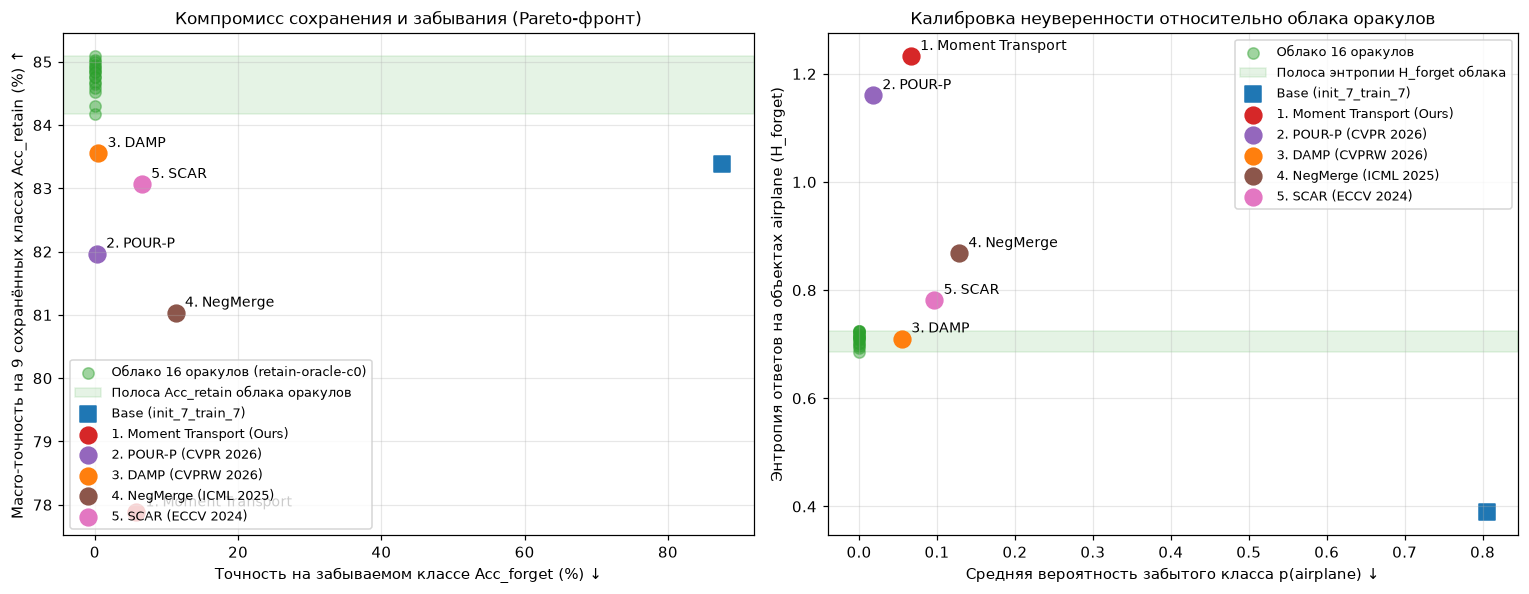

In [10]:
method_evals: list[ModelEvaluation] = [
    eval_moment,
    eval_pour,
    eval_damp,
    eval_negmerge,
    eval_scar,
]
matched_oracle_eval = oracle_evals[BASE_RUN_NAME]


def format_top_answers(top_answers: list[tuple[str, float]], limit: int = 3) -> str:
    return ", ".join(
        f"{cls_name}:{share:.2f}" for cls_name, share in top_answers[:limit]
    )


cloud_retain_vals = np.array([ev.retain_acc for ev in oracle_evals.values()])
cloud_forget_vals = np.array([ev.forget_acc for ev in oracle_evals.values()])
cloud_prob_vals = np.array([ev.forget_prob for ev in oracle_evals.values()])
cloud_ent_vals = np.array([ev.forget_entropy for ev in oracle_evals.values()])
cloud_aus_vals = np.array([ev.aus for ev in oracle_evals.values()])
cloud_mean_pred_dist = np.mean(
    [ev.pred_dist_on_forget for ev in oracle_evals.values()], axis=0
)
cloud_top_idx = np.argsort(-cloud_mean_pred_dist)[:3]
cloud_top_str = ", ".join(
    f"{CLASS_NAMES[int(i)]}:{cloud_mean_pred_dist[int(i)]:.2f}" for i in cloud_top_idx
)

summary_rows = [
    {
        "Модель / Метод": base_eval.name,
        "Acc_retain ↑": base_eval.retain_acc,
        "Acc_forget ↓": base_eval.forget_acc,
        "p(airplane) ↓": base_eval.forget_prob,
        "H_forget (эталон ~0.71)": base_eval.forget_entropy,
        "AUS ↑": base_eval.aus,
        "Время (с)": base_eval.elapsed_sec,
        "Топ-3 ответа на airplane": format_top_answers(base_eval.top_answers),
    },
    {
        "Модель / Метод": f"Oracle ({BASE_RUN_NAME})",
        "Acc_retain ↑": matched_oracle_eval.retain_acc,
        "Acc_forget ↓": matched_oracle_eval.forget_acc,
        "p(airplane) ↓": matched_oracle_eval.forget_prob,
        "H_forget (эталон ~0.71)": matched_oracle_eval.forget_entropy,
        "AUS ↑": matched_oracle_eval.aus,
        "Время (с)": np.nan,
        "Топ-3 ответа на airplane": format_top_answers(matched_oracle_eval.top_answers),
    },
    {
        "Модель / Метод": "Oracle Cloud (16 сидов, mean)",
        "Acc_retain ↑": float(cloud_retain_vals.mean()),
        "Acc_forget ↓": float(cloud_forget_vals.mean()),
        "p(airplane) ↓": float(cloud_prob_vals.mean()),
        "H_forget (эталон ~0.71)": float(cloud_ent_vals.mean()),
        "AUS ↑": float(cloud_aus_vals.mean()),
        "Время (с)": np.nan,
        "Топ-3 ответа на airplane": cloud_top_str,
    },
]

for ev in method_evals:
    summary_rows.append(
        {
            "Модель / Метод": ev.name,
            "Acc_retain ↑": ev.retain_acc,
            "Acc_forget ↓": ev.forget_acc,
            "p(airplane) ↓": ev.forget_prob,
            "H_forget (эталон ~0.71)": ev.forget_entropy,
            "AUS ↑": ev.aus,
            "Время (с)": ev.elapsed_sec,
            "Топ-3 ответа на airplane": format_top_answers(ev.top_answers),
        }
    )

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Левая панель: Acc_retain vs Acc_forget
ax = axes[0]
ax.scatter(
    cloud_forget_vals * 100,
    cloud_retain_vals * 100,
    color="#2ca02c",
    alpha=0.45,
    s=55,
    label="Облако 16 оракулов (retain-oracle-c0)",
)
ax.axhspan(
    cloud_retain_vals.min() * 100,
    cloud_retain_vals.max() * 100,
    color="#2ca02c",
    alpha=0.12,
    label="Полоса Acc_retain облака оракулов",
)
ax.scatter(
    [base_eval.forget_acc * 100],
    [base_eval.retain_acc * 100],
    color="#1f77b4",
    marker="s",
    s=110,
    label=base_eval.name,
)

palette = ["#d62728", "#9467bd", "#ff7f0e", "#8c564b", "#e377c2"]
for ev, color in zip(method_evals, palette, strict=True):
    ax.scatter(
        [ev.forget_acc * 100], [ev.retain_acc * 100], color=color, s=120, label=ev.name
    )
    ax.annotate(
        ev.name.split("(")[0].strip(),
        (ev.forget_acc * 100, ev.retain_acc * 100),
        xytext=(6, 4),
        textcoords="offset points",
        fontsize=9,
    )

ax.set_xlabel("Точность на забываемом классе Acc_forget (%) ↓")
ax.set_ylabel("Macro-точность на 9 сохранённых классах Acc_retain (%) ↑")
ax.set_title("Компромисс сохранения и забывания (Pareto-фронт)")
ax.legend(loc="lower left", fontsize=8.5)

# Правая панель: Энтропия H_forget vs вероятность p(airplane)
ax2 = axes[1]
ax2.scatter(
    cloud_prob_vals,
    cloud_ent_vals,
    color="#2ca02c",
    alpha=0.45,
    s=55,
    label="Облако 16 оракулов",
)
ax2.axhspan(
    cloud_ent_vals.min(),
    cloud_ent_vals.max(),
    color="#2ca02c",
    alpha=0.12,
    label="Полоса энтропии H_forget облака",
)
ax2.scatter(
    [base_eval.forget_prob],
    [base_eval.forget_entropy],
    color="#1f77b4",
    marker="s",
    s=110,
    label=base_eval.name,
)

for ev, color in zip(method_evals, palette, strict=True):
    ax2.scatter(
        [ev.forget_prob], [ev.forget_entropy], color=color, s=120, label=ev.name
    )
    ax2.annotate(
        ev.name.split("(")[0].strip(),
        (ev.forget_prob, ev.forget_entropy),
        xytext=(6, 4),
        textcoords="offset points",
        fontsize=9,
    )

ax2.set_xlabel("Средняя вероятность забытого класса p(airplane) ↓")
ax2.set_ylabel("Энтропия ответов на объектах airplane (H_forget)")
ax2.set_title("Калибровка неуверенности относительно облака оракулов")
ax2.legend(loc="upper right", fontsize=8.5)

plt.tight_layout()
plt.show()

### 6.2. Восстановление распределения ответов (Distribution Restoration, arXiv:2607.19442)

Согласно критерию **Distribution Restoration** ([Yang & Yeung, 2026](https://arxiv.org/abs/2607.19442)), настоящее разобучение класса не просто зануляет его вероятность и не размазывает ответы равномерно по всем классам, а **воспроизводит структуру ошибок оракула** (например, для самолётов `airplane` все 16 оракулов облака чаще всего предсказывают `ship` и `bird`).

Измерим:
1. Внутренний разброс (шумовую полосу репликации) внутри облака 16 оракулов: дивергенцию Йенсена–Шеннона $d_{\text{JS}}(p_M \,\|\, \bar{p}_{\text{cloud}})$ между распределением ответов каждого оракула на объектах `airplane` и средним распределением остальных 15 оракулов облака.
2. Расстояние $d_{\text{JS}}(p_M \,\|\, \bar{p}_{\text{cloud}})$ для каждого из 5 методов разобучения.

,Модель / Метод,JS(pred || cloud) ↓,JS(soft || cloud) ↓,"L1(pred, cloud) ↓"
0,Шумовая полоса облака (max из 16 оракулов),0.0028,0.0007,0.0802
1,Base (init_7_train_7),0.5027,0.4306,1.7520
2,1. Moment Transport (Ours),0.1310,0.1229,0.7666
3,2. POUR-P (CVPR 2026),0.0976,0.0961,0.7403
4,3. DAMP (CVPRW 2026),0.0389,0.0519,0.4463
5,4. NegMerge (ICML 2025),0.0568,0.0593,0.4345
6,5. SCAR (ECCV 2024),0.0656,0.0657,0.5636


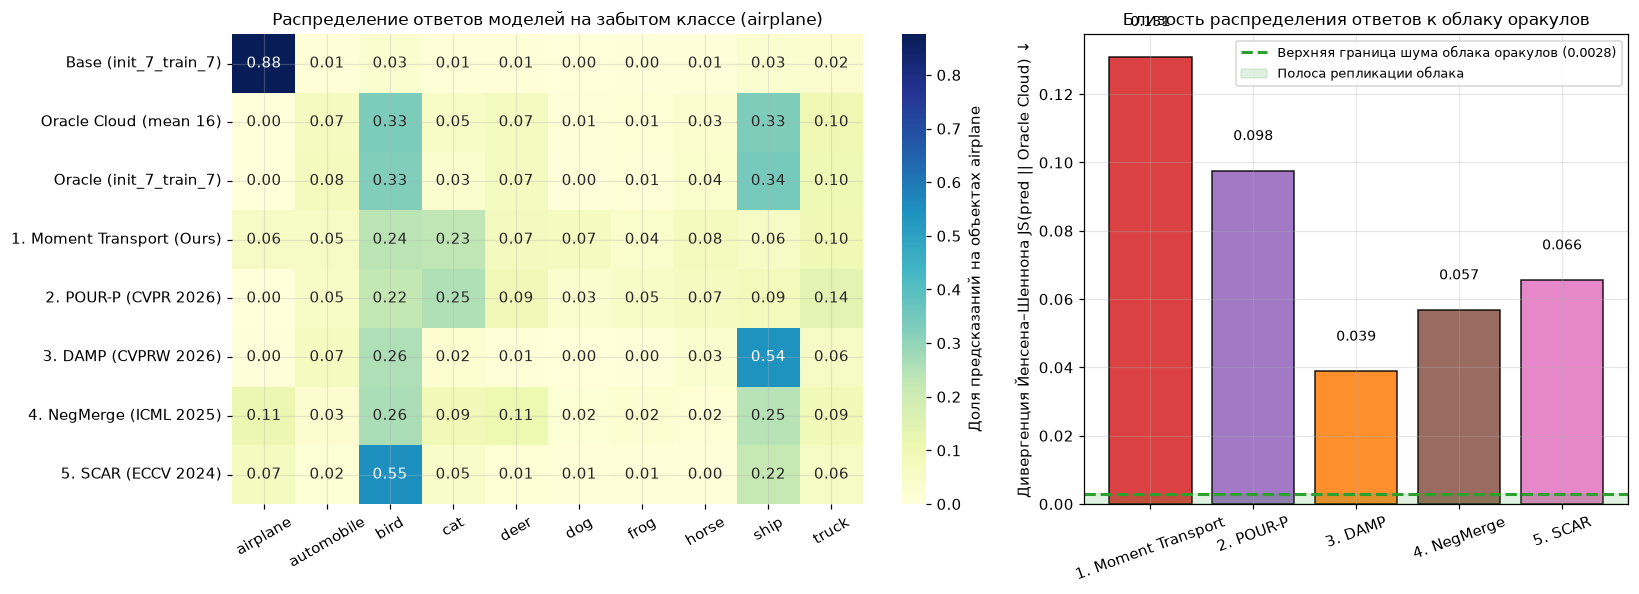

In [11]:
def jensen_shannon_divergence(
    p: np.ndarray, q: np.ndarray, eps: float = 1e-12
) -> float:
    p_norm = np.clip(p, eps, 1.0)
    p_norm = p_norm / p_norm.sum()
    q_norm = np.clip(q, eps, 1.0)
    q_norm = q_norm / q_norm.sum()
    m = 0.5 * (p_norm + q_norm)
    kl_pm = float(np.sum(p_norm * np.log(p_norm / m)))
    kl_qm = float(np.sum(q_norm * np.log(q_norm / m)))
    return 0.5 * (kl_pm + kl_qm)


oracle_pred_matrix = np.stack(
    [ev.pred_dist_on_forget for ev in oracle_evals.values()], axis=0
)
oracle_soft_matrix = np.stack(
    [ev.soft_dist_on_forget for ev in oracle_evals.values()], axis=0
)

# Leave-one-out JS-дивергенция каждого оракула до среднего по остальным 15 оракулам облака
oracle_loo_js_pred: list[float] = []
oracle_loo_js_soft: list[float] = []
for idx in range(len(oracle_evals)):
    others_pred = np.delete(oracle_pred_matrix, idx, axis=0).mean(axis=0)
    others_soft = np.delete(oracle_soft_matrix, idx, axis=0).mean(axis=0)
    oracle_loo_js_pred.append(
        jensen_shannon_divergence(oracle_pred_matrix[idx], others_pred)
    )
    oracle_loo_js_soft.append(
        jensen_shannon_divergence(oracle_soft_matrix[idx], others_soft)
    )

cloud_centroid_pred = oracle_pred_matrix.mean(axis=0)
cloud_centroid_soft = oracle_soft_matrix.mean(axis=0)

dist_rows = [
    {
        "Модель / Метод": "Шумовая полоса облака (max из 16 оракулов)",
        "JS(pred || cloud) ↓": float(np.max(oracle_loo_js_pred)),
        "JS(soft || cloud) ↓": float(np.max(oracle_loo_js_soft)),
        "L1(pred, cloud) ↓": float(
            np.max(np.abs(oracle_pred_matrix - cloud_centroid_pred).sum(axis=1))
        ),
    },
    {
        "Модель / Метод": base_eval.name,
        "JS(pred || cloud) ↓": jensen_shannon_divergence(
            base_eval.pred_dist_on_forget, cloud_centroid_pred
        ),
        "JS(soft || cloud) ↓": jensen_shannon_divergence(
            base_eval.soft_dist_on_forget, cloud_centroid_soft
        ),
        "L1(pred, cloud) ↓": float(
            np.abs(base_eval.pred_dist_on_forget - cloud_centroid_pred).sum()
        ),
    },
]

for ev in method_evals:
    dist_rows.append(
        {
            "Модель / Метод": ev.name,
            "JS(pred || cloud) ↓": jensen_shannon_divergence(
                ev.pred_dist_on_forget, cloud_centroid_pred
            ),
            "JS(soft || cloud) ↓": jensen_shannon_divergence(
                ev.soft_dist_on_forget, cloud_centroid_soft
            ),
            "L1(pred, cloud) ↓": float(
                np.abs(ev.pred_dist_on_forget - cloud_centroid_pred).sum()
            ),
        }
    )

dist_df = pd.DataFrame(dist_rows)
display(dist_df)

fig, axes = plt.subplots(
    1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.45, 1.0]}
)

heatmap_models = [
    ("Base (init_7_train_7)", base_eval.pred_dist_on_forget),
    ("Oracle Cloud (mean 16)", cloud_centroid_pred),
    ("Oracle (init_7_train_7)", matched_oracle_eval.pred_dist_on_forget),
] + [(ev.name, ev.pred_dist_on_forget) for ev in method_evals]

hm_matrix = np.stack([row[1] for row in heatmap_models], axis=0)
hm_labels = [row[0] for row in heatmap_models]

sns.heatmap(
    hm_matrix,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    xticklabels=CLASS_NAMES,
    yticklabels=hm_labels,
    cbar_kws={"label": "Доля предсказаний на объектах airplane"},
    ax=axes[0],
)
axes[0].set_title("Распределение ответов моделей на забытом классе (airplane)")
axes[0].tick_params(axis="x", rotation=30)

bar_names = [ev.name.split("(")[0].strip() for ev in method_evals]
bar_js = [
    jensen_shannon_divergence(ev.pred_dist_on_forget, cloud_centroid_pred)
    for ev in method_evals
]
noise_band_max = float(np.max(oracle_loo_js_pred))
noise_band_mean = float(np.mean(oracle_loo_js_pred))

bars = axes[1].bar(bar_names, bar_js, color=palette, alpha=0.88, edgecolor="black")
axes[1].axhline(
    noise_band_max,
    color="#2ca02c",
    linestyle="--",
    linewidth=2,
    label=f"Верхняя граница шума облака оракулов ({noise_band_max:.4f})",
)
axes[1].axhspan(
    0.0, noise_band_max, color="#2ca02c", alpha=0.14, label="Полоса репликации облака"
)
for bar, val in zip(bars, bar_js, strict=True):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2.0,
        val + 0.008,
        f"{val:.3f}",
        ha="center",
        va="bottom",
        fontsize=9,
    )

axes[1].set_ylabel("Дивергенция Йенсена–Шеннона JS(pred || Oracle Cloud) ↓")
axes[1].set_title("Близость распределения ответов к облаку оракулов")
axes[1].tick_params(axis="x", rotation=20)
axes[1].legend(loc="upper right", fontsize=8.5)

plt.tight_layout()
plt.show()

### 6.3. Геометрия представлений (`S2_embedding`), шумовая полоса репликации и диагностика bias

Поверхностное совпадение логитов не гарантирует удаления структуры класса из представлений ([Kim et al., 2025](https://arxiv.org/abs/2503.06991); [Hatami et al., 2026](https://arxiv.org/abs/2604.15166)). Поэтому на слое эмбеддингов `S2_embedding` ($h \in \mathbb{R}^{128}$) проводим параметрический и геометрический аудит относительно всех 16 моделей облака оракулов:

1. **Linear CKA на забытом и сохранённых классах** ($\text{CKA}_f^{(r)}$, $\text{CKA}_r^{(r)}$) и гармонический индекс **RUS (Representation Unlearning Score)** относительно облака оракулов ([Le et al., CVPR 2026](https://arxiv.org/abs/2511.19339)).
2. **Gauge-скорректированное ортогональное расстояние Прокруста** $d_{\text{Proc}}(M, \text{Oracle Cloud})$:
   $$d_{\text{Proc}}(X, Y) = \min_{Q^\top Q = I} \frac{\|X_c Q - Y_c\|_F}{\|Y_c\|_F}$$
   Между парами оракулов внутри облака $(O_i, O_j)$ это расстояние задаёт **шумовую полосу репликации представлений**.
3. **Сдвиг логит-смещения** $\Delta b_{c_0} = b_{c_0}^{M} - b_{c_0}^{\text{base}}$: показывает, опирается ли метод на прямое подавление bias выходного слоя или на изменение внутренних представлений.

Шумовая полоса репликации облака 16 оракулов (120 пар на S2_embedding):
  CKA_forget: 0.8008 ± 0.0222 [0.7600, 0.8737]
  CKA_retain: 0.9383 ± 0.0064 [0.9285, 0.9538]
  Procrustes rel-L2 (forget): 0.6408 ± 0.0199 [0.5779, 0.6697]


,Модель / Метод,"CKA_forget(M, Base) ↓","CKA_forget(M, Cloud) ↑","CKA_retain(M, Cloud) ↑",RUS^(r) ↑,"d_Proc_forget(M, Cloud) ↓",Δ bias (head[4].b_0),В полосе CKA облака,В полосе Procrustes облака
0,Oracle Cloud (внутриоблачный эталон),0.7142,0.8008,0.9383,0.8641,0.6408,-0.1402,True,True
1,Base (init_7_train_7),1.0000,0.7142,0.9260,0.8064,0.7088,0.0000,False,False
2,1. Moment Transport (Ours),1.0000,0.7142,0.9260,0.8064,0.7088,-1.7303,False,False
3,2. POUR-P (CVPR 2026),1.0000,0.7142,0.9260,0.8064,0.7088,-3.3571,False,False
4,3. DAMP (CVPRW 2026),0.8895,0.7062,0.9243,0.8007,0.7147,0.0000,False,False
5,4. NegMerge (ICML 2025),0.9110,0.7191,0.9049,0.8014,0.7111,-0.0156,False,False
6,5. SCAR (ECCV 2024),0.8607,0.7227,0.9207,0.8098,0.7203,-0.0027,False,False


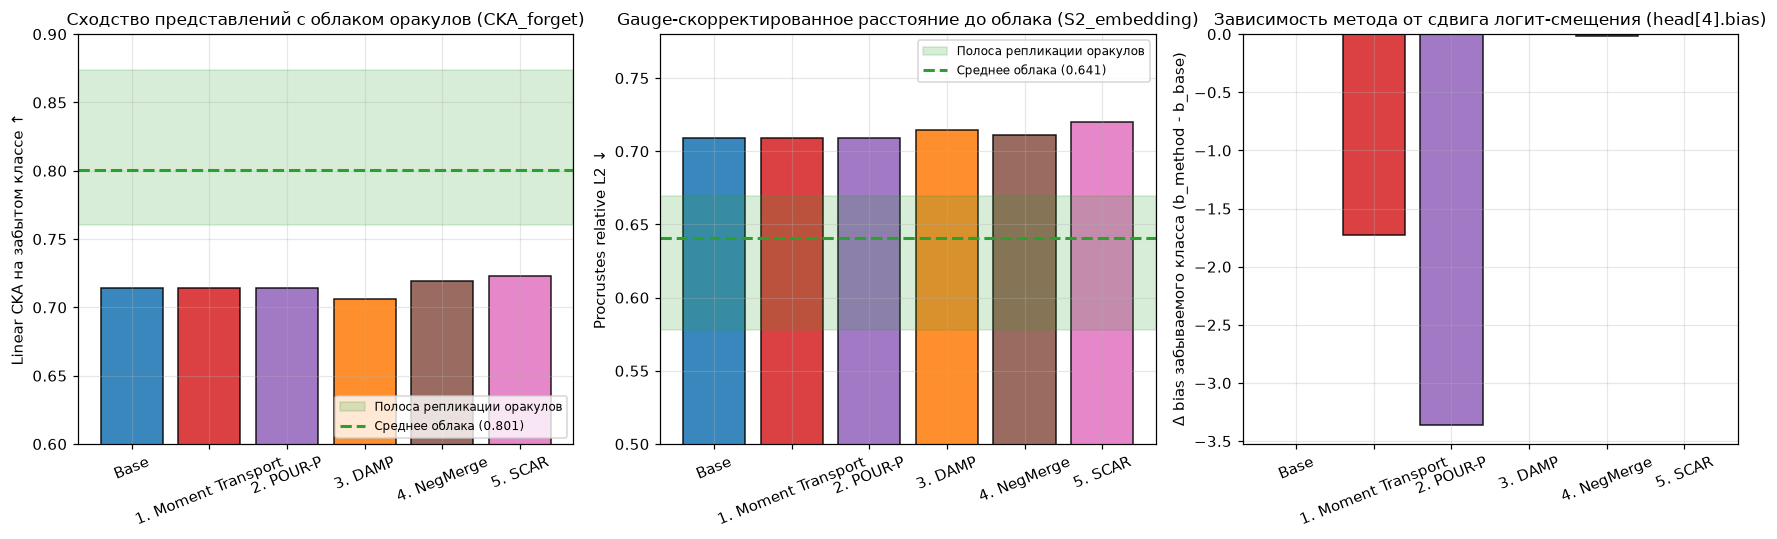

In [12]:
def linear_cka(x: Tensor, y: Tensor) -> float:
    xc = x - x.mean(dim=0, keepdim=True)
    yc = y - y.mean(dim=0, keepdim=True)
    xty = xc.T @ yc
    num = float((xty * xty).sum().item())
    xtx = xc.T @ xc
    yty = yc.T @ yc
    den = float(
        torch.sqrt((xtx * xtx).sum() * (yty * yty).sum()).clamp_min(1e-12).item()
    )
    return num / den


def procrustes_relative_l2(x: Tensor, y: Tensor) -> float:
    xc = x - x.mean(dim=0, keepdim=True)
    yc = y - y.mean(dim=0, keepdim=True)
    xc = xc / xc.norm().clamp_min(1e-12)
    yc = yc / yc.norm().clamp_min(1e-12)
    u, _, vt = torch.linalg.svd(xc.T @ yc, full_matrices=False)
    r_ortho = u @ vt
    return float((xc @ r_ortho - yc).norm().item() / yc.norm().clamp_min(1e-12).item())


f_test_mask = test_y == FORGET_CLASS
# Сбалансированный срез теста (2000 примеров) для быстрых попарных сравнений с 16 оракулами
eval_sub_idx = torch.cat(
    [torch.where(test_y == c)[0][:200] for c in range(NUM_CLASSES)]
)
f_sub_mask = test_y[eval_sub_idx] == FORGET_CLASS
r_sub_mask = ~f_sub_mask

oracle_names_list = list(oracle_evals.keys())
oracle_embs_sub = {
    name: oracle_evals[name].test_embeddings[eval_sub_idx] for name in oracle_names_list
}

# 1. Шумовая полоса репликации внутри облака 16 оракулов (все 120 пар оракулов)
pairwise_cka_f: list[float] = []
pairwise_cka_r: list[float] = []
pairwise_proc_all: list[float] = []
pairwise_proc_f: list[float] = []

for i in range(len(oracle_names_list)):
    for j in range(i + 1, len(oracle_names_list)):
        ei = oracle_embs_sub[oracle_names_list[i]]
        ej = oracle_embs_sub[oracle_names_list[j]]
        pairwise_cka_f.append(linear_cka(ei[f_sub_mask], ej[f_sub_mask]))
        pairwise_cka_r.append(linear_cka(ei[r_sub_mask], ej[r_sub_mask]))
        pairwise_proc_all.append(procrustes_relative_l2(ei, ej))
        pairwise_proc_f.append(procrustes_relative_l2(ei[f_sub_mask], ej[f_sub_mask]))

print(
    f"Шумовая полоса репликации облака 16 оракулов (120 пар на S2_embedding):\n"
    f"  CKA_forget: {np.mean(pairwise_cka_f):.4f} ± {np.std(pairwise_cka_f):.4f} "
    f"[{np.min(pairwise_cka_f):.4f}, {np.max(pairwise_cka_f):.4f}]\n"
    f"  CKA_retain: {np.mean(pairwise_cka_r):.4f} ± {np.std(pairwise_cka_r):.4f} "
    f"[{np.min(pairwise_cka_r):.4f}, {np.max(pairwise_cka_r):.4f}]\n"
    f"  Procrustes rel-L2 (forget): {np.mean(pairwise_proc_f):.4f} ± {np.std(pairwise_proc_f):.4f} "
    f"[{np.min(pairwise_proc_f):.4f}, {np.max(pairwise_proc_f):.4f}]"
)


def evaluate_representation_vs_cloud(
    ev: ModelEvaluation,
) -> dict[str, float | str | bool]:
    emb = ev.test_embeddings[eval_sub_idx]
    cka_f_vals = [
        linear_cka(emb[f_sub_mask], o_emb[f_sub_mask])
        for o_emb in oracle_embs_sub.values()
    ]
    cka_r_vals = [
        linear_cka(emb[r_sub_mask], o_emb[r_sub_mask])
        for o_emb in oracle_embs_sub.values()
    ]
    proc_f_vals = [
        procrustes_relative_l2(emb[f_sub_mask], o_emb[f_sub_mask])
        for o_emb in oracle_embs_sub.values()
    ]

    mean_cka_f = float(np.mean(cka_f_vals))
    mean_cka_r = float(np.mean(cka_r_vals))
    rus_r = (2.0 * mean_cka_f * mean_cka_r) / max(mean_cka_f + mean_cka_r, 1e-12)
    mean_proc_f = float(np.mean(proc_f_vals))

    base_emb = base_eval.test_embeddings[eval_sub_idx]
    cka_f_to_base = linear_cka(emb[f_sub_mask], base_emb[f_sub_mask])

    in_cka_band = mean_cka_f >= float(np.min(pairwise_cka_f))
    in_proc_band = mean_proc_f <= float(np.max(pairwise_proc_f))

    return {
        "Модель / Метод": ev.name,
        "CKA_forget(M, Base) ↓": cka_f_to_base,
        "CKA_forget(M, Cloud) ↑": mean_cka_f,
        "CKA_retain(M, Cloud) ↑": mean_cka_r,
        "RUS^(r) ↑": rus_r,
        "d_Proc_forget(M, Cloud) ↓": mean_proc_f,
        "Δ bias (head[4].b_0)": ev.forget_bias - base_eval.forget_bias,
        "В полосе CKA облака": in_cka_band,
        "В полосе Procrustes облака": in_proc_band,
    }


rep_rows = [
    {
        "Модель / Метод": "Oracle Cloud (внутриоблачный эталон)",
        "CKA_forget(M, Base) ↓": float(
            np.mean(
                [
                    linear_cka(
                        o_emb[f_sub_mask],
                        base_eval.test_embeddings[eval_sub_idx][f_sub_mask],
                    )
                    for o_emb in oracle_embs_sub.values()
                ]
            )
        ),
        "CKA_forget(M, Cloud) ↑": float(np.mean(pairwise_cka_f)),
        "CKA_retain(M, Cloud) ↑": float(np.mean(pairwise_cka_r)),
        "RUS^(r) ↑": float(
            2.0
            * np.mean(pairwise_cka_f)
            * np.mean(pairwise_cka_r)
            / (np.mean(pairwise_cka_f) + np.mean(pairwise_cka_r))
        ),
        "d_Proc_forget(M, Cloud) ↓": float(np.mean(pairwise_proc_f)),
        "Δ bias (head[4].b_0)": float(
            np.mean([ev.forget_bias for ev in oracle_evals.values()])
            - base_eval.forget_bias
        ),
        "В полосе CKA облака": True,
        "В полосе Procrustes облака": True,
    },
    evaluate_representation_vs_cloud(base_eval),
]

for ev in method_evals:
    rep_rows.append(evaluate_representation_vs_cloud(ev))

rep_df = pd.DataFrame(rep_rows)
display(rep_df)

fig, axes = plt.subplots(1, 3, figsize=(16, 5.0))

models_short = ["Base"] + [ev.name.split("(")[0].strip() for ev in method_evals]
cka_f_cloud_vals = [rep_rows[1]["CKA_forget(M, Cloud) ↑"]] + [
    row["CKA_forget(M, Cloud) ↑"] for row in rep_rows[2:]
]
proc_f_cloud_vals = [rep_rows[1]["d_Proc_forget(M, Cloud) ↓"]] + [
    row["d_Proc_forget(M, Cloud) ↓"] for row in rep_rows[2:]
]
bias_shift_vals = [0.0] + [row["Δ bias (head[4].b_0)"] for row in rep_rows[2:]]
bar_colors = ["#1f77b4"] + palette

# Панель 1: CKA_forget до облака оракулов
axes[0].bar(
    models_short, cka_f_cloud_vals, color=bar_colors, alpha=0.88, edgecolor="black"
)
axes[0].axhspan(
    float(np.min(pairwise_cka_f)),
    float(np.max(pairwise_cka_f)),
    color="#2ca02c",
    alpha=0.18,
    label="Полоса репликации оракулов",
)
axes[0].axhline(
    float(np.mean(pairwise_cka_f)),
    color="#2ca02c",
    linestyle="--",
    linewidth=2,
    label=f"Среднее облака ({np.mean(pairwise_cka_f):.3f})",
)
axes[0].set_ylim(0.60, 0.90)
axes[0].set_ylabel("Linear CKA на забытом классе ↑")
axes[0].set_title("Сходство представлений с облаком оракулов (CKA_forget)")
axes[0].tick_params(axis="x", rotation=22)
axes[0].legend(loc="lower right", fontsize=8)

# Панель 2: Procrustes relative L2 до облака оракулов
axes[1].bar(
    models_short, proc_f_cloud_vals, color=bar_colors, alpha=0.88, edgecolor="black"
)
axes[1].axhspan(
    float(np.min(pairwise_proc_f)),
    float(np.max(pairwise_proc_f)),
    color="#2ca02c",
    alpha=0.18,
    label="Полоса репликации оракулов",
)
axes[1].axhline(
    float(np.mean(pairwise_proc_f)),
    color="#2ca02c",
    linestyle="--",
    linewidth=2,
    label=f"Среднее облака ({np.mean(pairwise_proc_f):.3f})",
)
axes[1].set_ylim(0.50, 0.78)
axes[1].set_ylabel("Procrustes relative L2 ↓")
axes[1].set_title("Gauge-скорректированное расстояние до облака (S2_embedding)")
axes[1].tick_params(axis="x", rotation=22)
axes[1].legend(loc="upper right", fontsize=8)

# Панель 3: Сдвиг финального смещения head[4].bias[0]
axes[2].bar(
    models_short, bias_shift_vals, color=bar_colors, alpha=0.88, edgecolor="black"
)
axes[2].axhline(0.0, color="black", linewidth=1)
axes[2].set_ylabel("Δ bias забываемого класса (b_method - b_base)")
axes[2].set_title("Зависимость метода от сдвига логит-смещения (head[4].bias)")
axes[2].tick_params(axis="x", rotation=22)

plt.tight_layout()
plt.show()

## 7. Основные выводы сравнения

1. **Профиль облака из 16 оракулов (`retain-oracle-c0`) задаёт строгий коридор приёмки:**
   - На 9 сохранённых классах все 16 оракулов точнее базовой модели: $\text{Acc}_{\text{retain}} = 0.8475 \pm 0.0026$ (коридор $[0.8417, 0.8509]$) против $0.8339$ у `full-baseline/init_7_train_7`.
   - На объектах забытого класса `airplane` оракулы выдают $p(\text{airplane}) = 2.13 \cdot 10^{-6}$ и устойчивую структуру перераспределения ответов (`bird`: $33\%$, `ship`: $33\%$, `truck`: $10\%$) со средней энтропией $H_{\text{forget}} = 0.7101 \pm 0.0120$ (коридор $[0.6850, 0.7249]$).
   - По AUS (без обрезки, как в оригинальной формулировке) облако даёт $\text{AUS} = 1.0136 \pm 0.0026$, коридор $[1.0078, 1.0170]$: значения выше $1$ — премия за то, что оракулы точнее базы на сохранённых классах. Обрезанная версия схлопывала все 16 оракулов в $1.0000$ и делала коридор нулевой ширины.
2. **DAMP (CVPRW 2026) ближе всех к эталонному облаку оракулов по поведению и селективности:**
   - Единственный метод, который **повышает** $\text{Acc}_{\text{retain}}$ относительно базовой модели ($0.8339 \to 0.8356$, приближаясь к облаку оракулов $0.8475$) при снижении $\text{Acc}_{\text{forget}}$ до $0.0050$ ($\text{AUS} = 0.9967$). При этом до коридора облака $\text{AUS} = 1.0136 \pm 0.0026$ остаётся разрыв $6.5\sigma$: поведенчески метод ближе всех, но внутрь полосы не входит.
   - Точно попадает в полосу энтропии облака оракулов ($H_{\text{forget}} = 0.7105$ при коридоре облака $[0.6850, 0.7249]$) и даёт минимальную дивергенцию Йенсена–Шеннона с распределением ответов облака оракулов среди методов ($\text{JS} = 0.0389$; шумовая полоса облака по этой же метрике — $0.0028$, то есть DAMP всё ещё в $14$ раз выше неё), воспроизводя доминирующие ответы `ship` ($54\%$) и `bird` ($26\%$).
   - В отличие от методов, правящих только выходную голову (`Moment Transport`, `POUR-P`), **DAMP** меняет представления `S2_embedding` ($\text{CKA}_{\text{forget}}(M, \text{Base})$ падает с $1.0000$ до $0.8895$) при **нулевом** сдвиге финального смещения $\Delta b_{c_0} = 0.0000$.
3. **Замкнутые методы в голове (`Moment Transport` и `POUR-P`) работают за миллисекунды, но опираются на сильный сдвиг bias и не меняют скрытые представления:**
   - Кастомный метод **Moment Transport** ($A = \Sigma_r^{1/2}\Sigma_c^{-1/2}$) выполняется за $0.055$ с, снижает вероятность забываемого класса в $12$ раз ($0.8051 \to 0.0667$) и точность до $0.0580$, но поскольку матрица $A$ применяется ко всем 10 классам в `head[4]`, он сильнее размывает ответы ($H_{\text{forget}} = 1.2328$) и снижает $\text{Acc}_{\text{retain}}$ до $0.7788$.
   - **POUR-P** (CVPR 2026) за счёт одномерного ортогонального проектора $P = I - v_u v_u^\top$ вдоль направления забываемого класса обнуляет $\text{Acc}_{\text{forget}}$ до $0.0030$ за $0.021$ с при меньшей потере $\text{Acc}_{\text{retain}}$ ($0.8197$, $\text{AUS} = 0.9828$), но опирается на сильный отрицательный сдвиг логит-смещения ($\Delta b_{c_0} = -3.3571$, у `Moment Transport` $\Delta b_{c_0} = -1.7303$) и оставляет представления `S2_embedding` неизменными ($\text{CKA}_{\text{forget}}(M, \text{Base}) = 1.0000$).
4. **Градиентные и весовые методы (`SCAR` и `NegMerge`) модифицируют представления, но уступают DAMP по балансу метрик:**
   - **SCAR** (ECCV 2024) за счёт стягивания признаков по Махаланобису и температурной JS-дистилляции удерживает высокую точность на сохранённых классах ($\text{Acc}_{\text{retain}} = 0.8307$, $\text{Acc}_{\text{forget}} = 0.0660$, $H_{\text{forget}} = 0.7816$) и сильнее всех сдвигает представления `S2_embedding` от базы к облаку оракулов ($\text{CKA}_{\text{forget}}(M, \text{Base}) = 0.8607$, $\text{CKA}_{\text{forget}}(M, \text{Cloud}) = 0.7227$, $\text{RUS}^{(r)} = 0.8098$).
   - **NegMerge** (ICML 2025) отфильтровывает $41.2\%$ знаково-конфликтных весов и перестраивает представления ($\text{CKA}_{\text{forget}}(M, \text{Base}) = 0.9110$, $\text{JS} = 0.0568$), демонстрируя плавный трейд-офф между силой вычитания $\lambda$ и сохранением точности ($\text{Acc}_{\text{retain}} = 0.8103$, $\text{Acc}_{\text{forget}} = 0.1130$).
5. **Ни один приближённый метод не попал внутрь внутриоблачной полосы репликации представлений (`CKA_forget` $\in [0.7600, 0.8737]$, `Procrustes rel-L2` $\in [0.5779, 0.6697]$):**
   - Это напрямую согласуется с выводом [Yang & Yeung, 2026 (arXiv:2607.19442)](https://arxiv.org/abs/2607.19442): даже когда поведенческие метрики ($\text{Acc}_{\text{retain}}$, $\text{Acc}_{\text{forget}}$, $H_{\text{forget}}$ у DAMP) попадают в коридор переобученных оракулов, в пространстве представлений между разобученной моделью и переобученным с нуля облаком оракулов сохраняется измеримый зазор ($\text{CKA}_{\text{forget}} \approx 0.71–0.72$ против $0.80$ внутри облака).
   - По AUS картина та же: коридор облака $[1.0078, 1.0170]$, и ни один метод в него не входит — DAMP $0.9967$, POUR-P $0.9828$, SCAR $0.9351$, Moment Transport $0.8931$, NegMerge $0.8773$. То есть сводный поведенческий индекс, посчитанный без обрезки, даёт тот же вердикт, что и метрики представлений, тогда как обрезанная версия делала этот разрыв невидимым ($0.9950$ против $1.0000$ при нулевой ширине коридора).